# Tutorial 02: Hospital Patient Cohort Ingestion & Inspection
This notebook walks through ingesting clinical data from `patients.csv`, computing summary statistics, and visualizing patient attributes.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load patient records using a relative path
df = pd.read_csv("../data/patients.csv")
print(f"Cohort Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Cohort Dimensions: 10 rows, 6 columns


,PatientID,Age,Sex,BloodPressure,Cholesterol,Diagnosis
0,P001,25,Female,120,200,Diabetes
1,P002,40,Male,130,180,Healthy
2,P003,65,Male,145,250,Diabetes
3,P004,50,Female,110,190,Healthy
4,P005,80,Male,200,300,Hypertension


### 1. Descriptive Summary Statistics
Review continuous metrics (Age, BloodPressure, Cholesterol) and frequency distributions across categorical features.


In [2]:
print("--- Numerical Feature Summaries ---")
display(df.describe())

print("\n--- Sex Distribution ---")
print(df['Sex'].value_counts())

print("\n--- Clinical Diagnosis Distribution ---")
print(df['Diagnosis'].value_counts())


--- Numerical Feature Summaries ---


,Age,BloodPressure,Cholesterol
count,10.000000,10.000000,10.000000
mean,46.200000,139.500000,230.000000
std,16.883917,35.870911,55.226805
min,25.000000,110.000000,180.000000
25%,35.750000,118.500000,192.500000
50%,42.500000,123.500000,212.500000
75%,53.750000,141.250000,242.500000
max,80.000000,210.000000,350.000000



--- Sex Distribution ---
Sex
Female    5
Male      5
Name: count, dtype: int64

--- Clinical Diagnosis Distribution ---
Diagnosis
Healthy         5
Diabetes        3
Hypertension    2
Name: count, dtype: int64


### 2. Clinical Visualization
Create a scatter plot of Patient Age vs. Serum Cholesterol, colored by Blood Pressure.


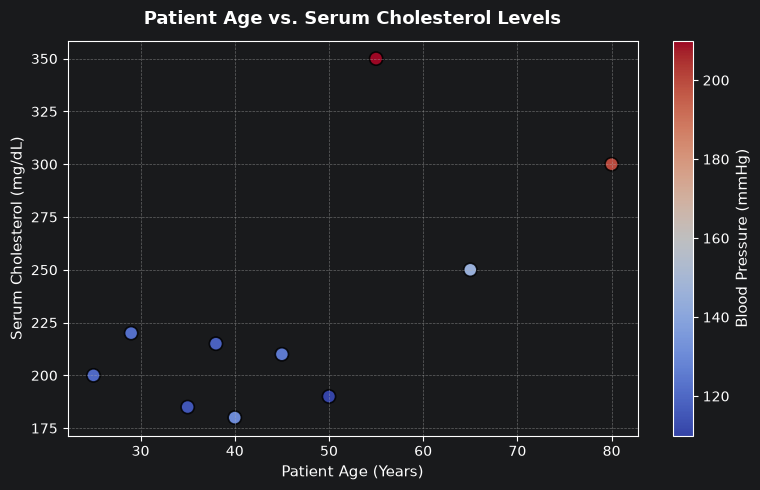

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))

scatter = ax.scatter(
    df['Age'], 
    df['Cholesterol'], 
    c=df['BloodPressure'], 
    cmap='coolwarm', 
    s=90, 
    alpha=0.85, 
    edgecolors='black',
    linewidth=1.2
)

cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label('Blood Pressure (mmHg)', fontsize=11)

ax.set_title("Patient Age vs. Serum Cholesterol Levels", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Patient Age (Years)", fontsize=11)
ax.set_ylabel("Serum Cholesterol (mg/dL)", fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
